### Import Modules

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

### Read Data File

In [22]:
df = pd.read_csv("train.csv")
print(df.shape)
df.head()

(4500, 73)


,project_id,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,...,forks,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,hours_spent,log_hours,hours_bucket
0,535ce026f7,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,...,0,0,0,0,False,0,1-2,32.2,3.4726,30-100
1,869ba41ed7,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,...,0,0,0,0,False,0,3-5,5.0,1.6094,<10
2,d6f81f8862,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,...,0,0,0,0,False,0,3-5,1.3,0.2624,<10
3,152b5d915d,4,1,0,frequent,0.0000,0.2500,6000,0,0.0000,...,0,0,0,0,False,0,<1,2.0,0.6931,<10
4,3b5f8a49e6,7,3,64,sporadic,0.8571,0.0000,800,0,0.0419,...,0,0,0,0,False,0,1-2,4.0,1.3863,<10


In [23]:
print(df['hours_spent'].describe())

count    4500.000000
mean       12.136178
std        19.047682
min         0.100000
25%         2.700000
50%         6.000000
75%        12.900000
max       140.700000
Name: hours_spent, dtype: float64


### Analize the distribution of the data

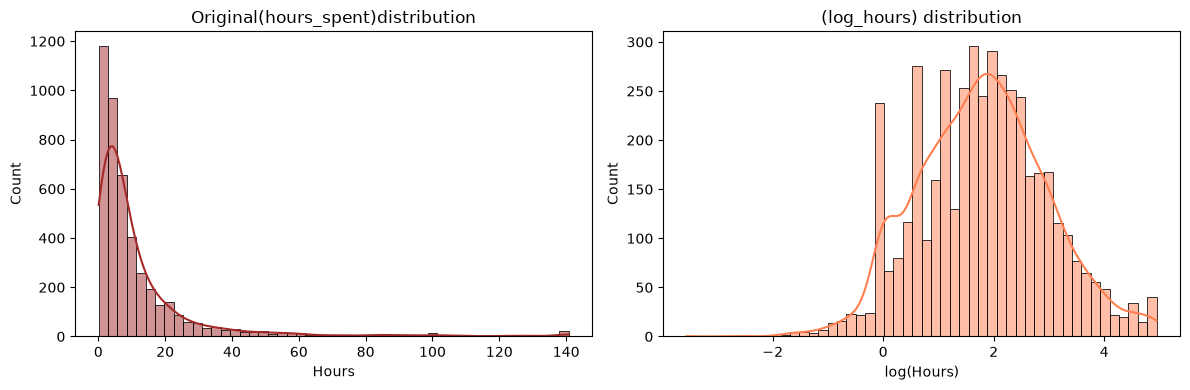

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['hours_spent'], bins=50, kde=True, ax=axes[0], color="brown")
axes[0].set_title("Original(hours_spent)distribution") 
axes[0].set_xlabel("Hours")

# log transform
sns.histplot(df["log_hours"], bins=50, kde=True, ax=axes[1], color="coral")
axes[1].set_title("(log_hours) distribution")
axes[1].set_xlabel("log(Hours)")

plt.tight_layout()
plt.show()

In [25]:
df['is_one_shot'] = df["pct_code_in_first_commit"] > 0.9
df.head()

,project_id,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,...,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,hours_spent,log_hours,hours_bucket,is_one_shot
0,535ce026f7,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,...,0,0,0,False,0,1-2,32.2,3.4726,30-100,False
1,869ba41ed7,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,...,0,0,0,False,0,3-5,5.0,1.6094,<10,False
2,d6f81f8862,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,...,0,0,0,False,0,3-5,1.3,0.2624,<10,False
3,152b5d915d,4,1,0,frequent,0.0000,0.2500,6000,0,0.0000,...,0,0,0,False,0,<1,2.0,0.6931,<10,False
4,3b5f8a49e6,7,3,64,sporadic,0.8571,0.0000,800,0,0.0419,...,0,0,0,False,0,1-2,4.0,1.3863,<10,False


In [26]:
result = df.groupby("is_one_shot")["hours_spent"].agg(["count", "mean", "median"])
print(result)

             count       mean  median
is_one_shot                          
False         3731  13.399544     7.0
True           769   6.006632     3.0


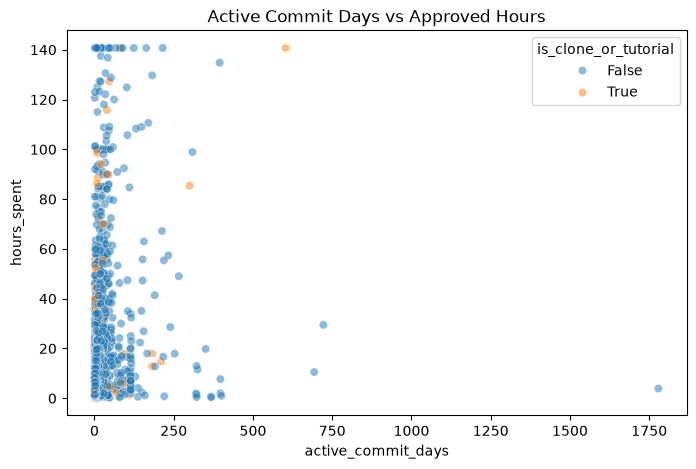

In [27]:
# 1. 准备一张宽 8 英寸、高 5 英寸的白纸
plt.figure(figsize=(8, 5))

# 2. 往白纸上画散点图
sns.scatterplot(
    data=df,
    x="active_commit_days",
    y="hours_spent",
    hue="is_clone_or_tutorial",
    alpha=0.5,
)

# 3. 写上标题并显示
plt.title("Active Commit Days vs Approved Hours")
plt.show()

### Separate the data

In [28]:
from sklearn.model_selection import train_test_split
train_part, val_part = train_test_split(
    df,
    test_size=0.2,  # 拿 20%（900行）出来当模拟考卷
    random_state=42,  # 固定随机种子，保证每次切出来的都是同一批，方便公平对比
    stratify=df[
        "hours_bucket"
    ],  # 关键！保证各时间段（<10, 10-30等）的比例完全一致 stratify的中文含义是：分层，具体作用是：从所选择的列（具体从axis分辨），按照相同比例抽取数据
)

train_part.to_csv("train_part.csv", index=False)
val_part.to_csv("val_part.csv", index=False)
print(train_part.shape, val_part.shape)

(3600, 74) (900, 74)


### Train the model (AI-assisted)

In [ ]:
from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split

y = df["hours_spent"]
X = df.drop(columns=['project_id', 'hours_spent', 'log_hours', 'hours_bucket'])
print(X.shape)
X.head() # check

(4500, 70)


,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,median_lines_per_commit,...,is_clone_or_tutorial,stars,forks,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,is_one_shot
0,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,128.5,...,False,2,0,0,0,0,False,0,1-2,False
1,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,32.0,...,False,1,0,0,0,0,False,0,3-5,False
2,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,64.5,...,False,0,0,0,0,0,False,0,3-5,False
3,4,1,0,frequent,0.0000,0.2500,6000,0,0.0000,1904.0,...,False,0,0,0,0,0,False,0,<1,False
4,7,3,64,sporadic,0.8571,0.0000,800,0,0.0419,198.0,...,False,0,0,0,0,0,False,0,1-2,False


### Deal with text strings in X

In [39]:
[c for c in X.columns if X[c].dtype == object]
# []的意思是：列表

['has_custom_art',
 'is_mobile_responsive',
 'is_multiplayer',
 'mentions_ai_api',
 'is_clone_or_tutorial']

### Deal with fake bool

In [40]:
# 第 1 类：假布尔（看起来是 True/False，其实是字符串，因为有 NaN）
fake_bool = [
    "has_custom_art",
    "is_mobile_responsive",
    "is_multiplayer",
    "mentions_ai_api",
    "is_clone_or_tutorial",
]
for col in fake_bool:
    X[col] = X[col].map({True: 1, False: 0, "True": 1, "False": 0}).fillna(0).astype(int)

# 第 2 类：序数（有大小顺序，可以映射成 0~3）
X["author_prior_projects"] = X["author_prior_projects"].map(
    {"0": 0, "1-2": 1, "3-5": 2, "6+": 3}
)
X["author_account_age_years"] = X["author_account_age_years"].map(
    {"<1": 0, "1-2": 1, "3-5": 2, "6+": 3}
)

# 第 3 类：真分类（没有大小顺序，交给 LightGBM 自己学）
cats = ["commit_cadence", "primary_language", "framework", "hosting_type", "project_category"]
for col in cats:
    X[col] = X[col].astype("category")

# 最后：真正的 bool 列统一转成 0/1
for col in X.columns:
    if X[col].dtype == bool:
        X[col] = X[col].astype(int)

# 验证
print("剩余 object 列:", [c for c in X.columns if X[c].dtype == object])
print("Total NaN:", X.isna().sum().sum())
print("Total inf:", np.isinf(X.select_dtypes("number")).sum().sum())
print("Shape:", X.shape)


剩余 object 列: []
Total NaN: 6338
Total inf: 0
Shape: (4500, 70)


### Learning RMSLE

In [ ]:
from sklearn.metrics import mean_squared_error
def rmsle(y_true, y_pred):
    """计算 RMSLE（均方对数误差）"""
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))) # np.log1p(x) 是ln(1+x)的numpy专用函数

In [ ]:
# test the rmsle function
y_true = [5, 10, 3]
y_pred = [7, 8, 3]
print(rmsle(y_true, y_pred))

0.20250901447212585


### Start model training process

In [ ]:
from sklearn.model_selection import cross_val_score, KFold